# Albedo bias from neglecting hyperillumination

The noiseless hyperillumination truth of one planet fitted with the point-source model (`naive`), $A_B$ and the baseline free: the bias of the recovered Bond albedo, whether a phase curve can detect it, and how it changes with the true $A_B$, the inclination and the limb darkening of the star. `02_redistribution_bias.ipynb` adds the heat redistribution $F$.

In [1]:
import numpy as np
import contextlib, io
import matplotlib.pyplot as plt
import pandas as pd
with contextlib.redirect_stdout(io.StringIO()):          # mute "no spidermanrc file detected"
    import fspiderman
from hyperphase.defaults import DEFAULT_A, DEFAULT_A_B, DEFAULT_N_BINS, DEFAULT_N_LA, DEFAULT_N_LO, DEFAULT_N_ORBITS, DEFAULT_U, DEFAULT_U_BOL
from hyperphase.plotting.irradiance import stellar_flux_line
from hyperphase.model import ConstantBandAlbedo, FittingConfig, model_pcurve
from hyperphase.phasecurve import full_PhaseCurve
from hyperphase.bands import filter_lambda, filter_loc, JWST_BANDS
from hyperphase.orbit import transit_duration_t14
from hyperphase.bias.detectors import retrieval_cfg
from hyperphase.bias.fisher import measurability
from hyperphase.bias.fits import bin_curve, fit_naive
from hyperphase.bias.sweeps import bias_sweep, bias_vs_true_AB, cfg_with_incl, cfg_with_u_bol
from hyperphase.plotting.bias import measurability_panel, plot_bias_sweep
from hyperphase.plotting.style import FIT_ZERO
from hyperphase.targets import hi_planets_by_name
from hyperphase.noise import rms_1min

In [2]:
planet = hi_planets_by_name("TOI-2431 b")   # from the NASA Exoplanet Archive, or a curated entry of inputs/planets/curated_planets.csv
period, incl, ecc, w, r1, r2, R, T2_eff, a_AU = planet.args
u, u_bol = DEFAULT_U, DEFAULT_U_BOL       # transit and irradiance limb darkening
A_B = DEFAULT_A_B                         # Bond albedo: sets the temperature map
A_model = ConstantBandAlbedo(DEFAULT_A)   # band albedo A of the reflected light, independent of A_B

instrument = "MIRI/LRS"   # or e.g. "JWST_NIRSpec.G395H_NRS1", "MIRI/F1280W"
filter_path = filter_loc(instrument)
lambda_range = filter_lambda(instrument)
l1, l2 = lambda_range

n_bins = DEFAULT_N_BINS                     # bins per orbit
minutes_binning = period*24*60/n_bins       # bin width [minutes]
sigma_1min = rms_1min(planet, instrument)   # noise per minute from PandExo
n_orbits = DEFAULT_N_ORBITS                 # orbits observed

A_B_true = A_B  # injected Bond albedo of the hyperillumination truth
SEED = 44   # the noise realisation of the MIRI/LRS example retrieval (retrievals/example_runs/), a typical one

# context for the bias-analysis functions imported from hyperphase.bias (fit range A_B_FIT_BOUNDS by default: A_B_fit may go below 0)
cfg = FittingConfig(planet=planet, filter_path=filter_path,
                 l1=l1, l2=l2, A_=A_model,
                 sigma_1min=sigma_1min, n_orbits=n_orbits, n_bins=n_bins,
                 reflected=True, u_bol=u_bol, u=u)
sigma_bin = cfg.sigma_bin # [ppm]
print(f"\nNoise Level (1min) = {sigma_1min:.1f} ppm")
print(f"period = {period*24*60:.1f} min -> {n_bins} bins of {minutes_binning:.1f} min")
print(f"1-sigma per bin = {sigma_bin:.1f} ppm")

TOI-2431 b [MIRI/LRS]: sigma_1min = 62.93 ppm/min from the PandExo cache

Noise Level (1min) = 62.9 ppm
period = 322.8 min -> 27 bins of 12.0 min
1-sigma per bin = 8.1 ppm


## 1. Detectability

`hyperillum` against `naive` at the true $A_B$, binned, with one mock observation (seed `SEED`) and its noise per bin: the phase curve with the transit, then without it.

In [3]:
# Full phase curve (reflected + thermal). The naive curve uses full_PhaseCurve(insolation_model="naive")
t_k, pc_k, fp_k = full_PhaseCurve(planet, lambda_range, u=u, filter_path=filter_path, A=A_model(A_B), A_B=A_B, N_LAYERS=40, n_lo=DEFAULT_N_LO, n_la=DEFAULT_N_LA, insolation_model="hyperillum", u_bol=u_bol)
t_n, pc_n, fp_n = full_PhaseCurve(planet, lambda_range, u=u, filter_path=filter_path, A=A_model(A_B), A_B=A_B, N_LAYERS=40, n_lo=DEFAULT_N_LO, n_la=DEFAULT_N_LA, insolation_model="naive", u_bol=u_bol)

# Transit removed (phase modulation + occultation only) = reflected(no transit) + thermal(no transit), so the modulation is visible
_, lc_k, _ = full_PhaseCurve(planet, lambda_range, u=u, filter_path=filter_path, A=A_model(A_B), A_B=A_B, N_LAYERS=40, n_lo=DEFAULT_N_LO, n_la=DEFAULT_N_LA, insolation_model="hyperillum", u_bol=u_bol, include_transit=False)
_, lc_n, _ = full_PhaseCurve(planet, lambda_range, u=u, filter_path=filter_path, A=A_model(A_B), A_B=A_B, N_LAYERS=40, n_lo=DEFAULT_N_LO, n_la=DEFAULT_N_LA, insolation_model="naive",      u_bol=u_bol, include_transit=False)

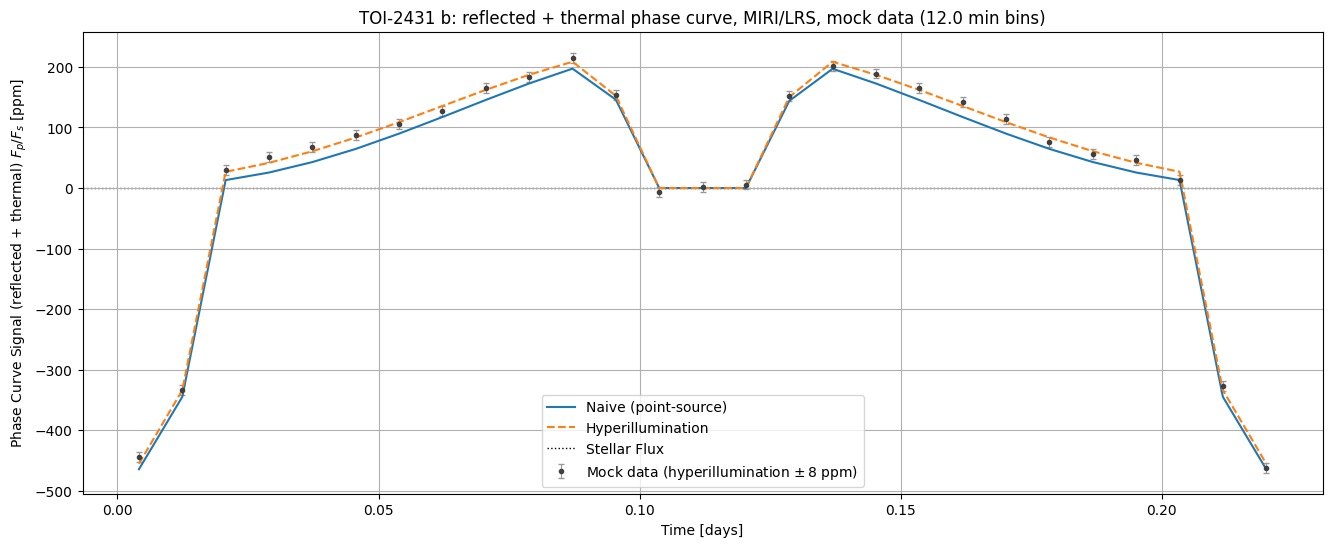

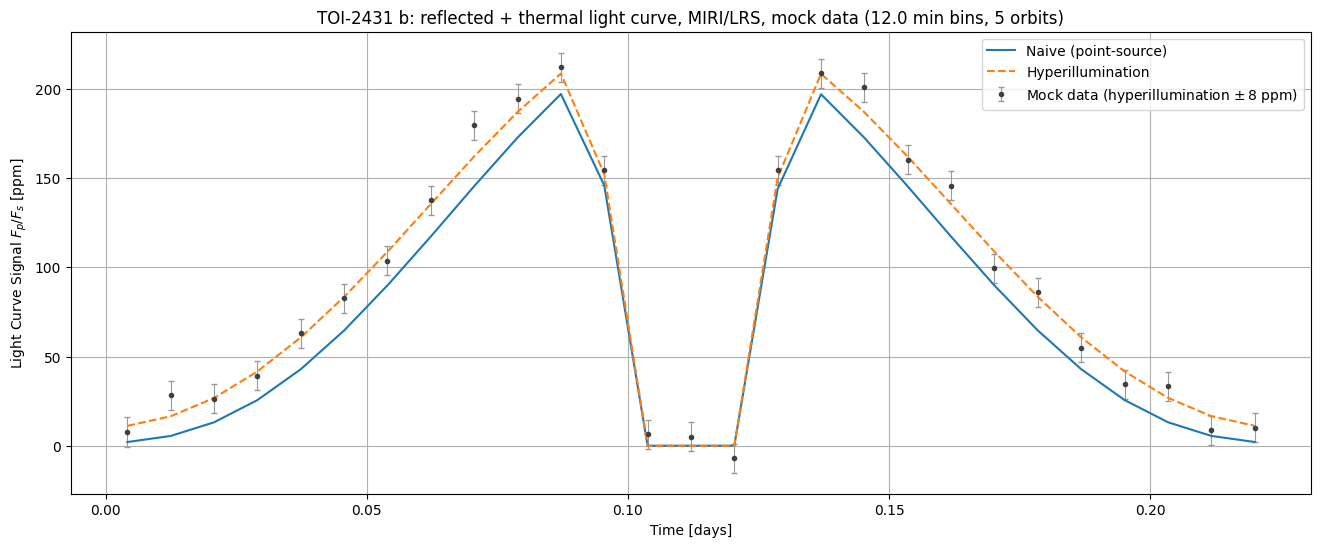

In [4]:
# Mock observation: at each binned time draw a data point ~ N(mean = hyperillum model, std = sigma_bin),
rng = np.random.default_rng(SEED)   # fixed seed -> reproducible mock data

# --- Phase curve ---
tb_n, yb_n = bin_curve(t_n, (pc_n - 1) * 1e6, minutes_binning)   # naive model, binned [ppm]
tb_k, yb_k = bin_curve(t_k, (pc_k - 1) * 1e6, minutes_binning)   # hyperillumination model, binned [ppm]
y_data = yb_k + rng.normal(0., sigma_bin, size=yb_k.size)        # mock data ~ N(hyperillum, sigma_bin)

plt.figure(figsize=(16, 6))
plt.errorbar(tb_k, y_data, yerr=sigma_bin, fmt="o", ms=3, color="0.25", ecolor="0.6", elinewidth=.8, capsize=2,
             label=rf"Mock data (hyperillumination $\pm\,{sigma_bin:.0f}$ ppm)")
plt.plot(tb_n, yb_n, linewidth=1.5, color="C0", label="Naive (point-source)")
plt.plot(tb_k, yb_k, linewidth=1.5, linestyle="--", color="C1", label="Hyperillumination")
stellar_flux_line()
plt.xlabel("Time [days]")
plt.ylabel(r"Phase Curve Signal (reflected + thermal) $F_p/F_s$ [ppm]")
plt.title(f"{planet.name}: reflected + thermal phase curve, {instrument}, mock data ({minutes_binning:.1f} min bins)")
plt.legend(); plt.grid()
plt.show()

# --- Light curve ---
tb_n, yb_n = bin_curve(t_n, lc_n * 1e6, minutes_binning)
tb_k, yb_k = bin_curve(t_k, lc_k * 1e6, minutes_binning)
y_data = yb_k + rng.normal(0., sigma_bin, size=yb_k.size)

plt.figure(figsize=(16, 6))
plt.errorbar(tb_k, y_data, yerr=sigma_bin, fmt="o", ms=3, color="0.25", ecolor="0.6", elinewidth=.8, capsize=2,
             label=rf"Mock data (hyperillumination $\pm\,{sigma_bin:.0f}$ ppm)")
plt.plot(tb_n, yb_n, linewidth=1.5, color="C0", label="Naive (point-source)")
plt.plot(tb_k, yb_k, linewidth=1.5, linestyle="--", color="C1", label="Hyperillumination")
plt.xlabel("Time [days]")
plt.ylabel(r"Light Curve Signal $F_p/F_s$ [ppm]")
plt.title(f"{planet.name}: reflected + thermal light curve, {instrument}, mock data ({minutes_binning:.1f} min bins, {n_orbits} orbits)")
plt.legend(); plt.grid()
plt.show()

## 2. Bias of the $A_B$-only fit

`fit_naive` with the baseline free, fitted to the noiseless truth. The figures show the best fit against the truth, and the residual before and after absorbing the bias into $A_B$.

In [5]:
# demo: fit the naive model (baseline free) to the hyperillumination truth and report the recovered-A_B bias
_, truth = model_pcurve(cfg, "hyperillum", A_B_true)
A_fit, chi2, rms = fit_naive(cfg, truth)
print(f"A_B: {A_B_true:.3f} -> {A_fit:.3f}  bias={A_fit-A_B_true:+.3f} "
      f"({100*(A_fit-A_B_true)/A_B_true:+.1f}%)  chi2={chi2:.3f}  "
      f"resid_rms={rms:.2f} ppm  significance={np.sqrt(chi2):.2f} sigma "
      f"({cfg.n_orbits} orbits, {cfg.n_bins} bins)")

A_B: 0.200 -> 0.140  bias=-0.060 (-29.9%)  chi2=12.635  resid_rms=5.57 ppm  significance=3.55 sigma (5 orbits, 27 bins)


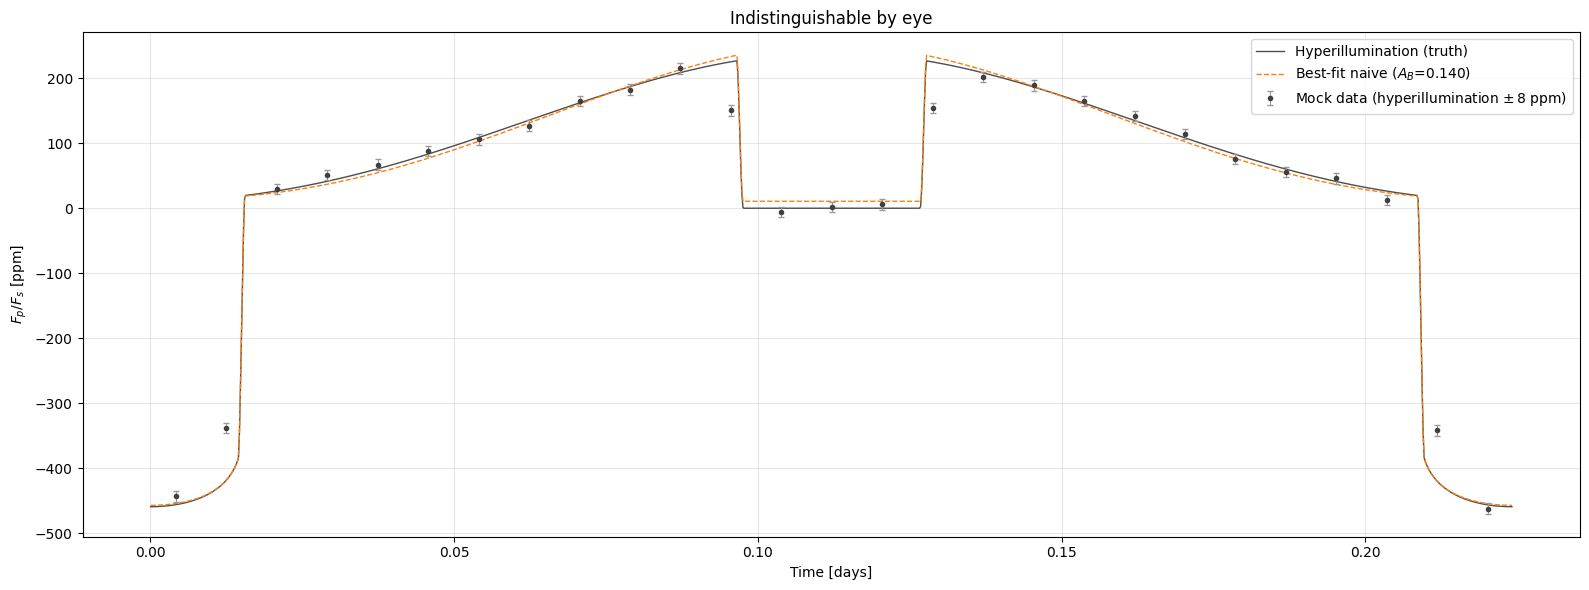

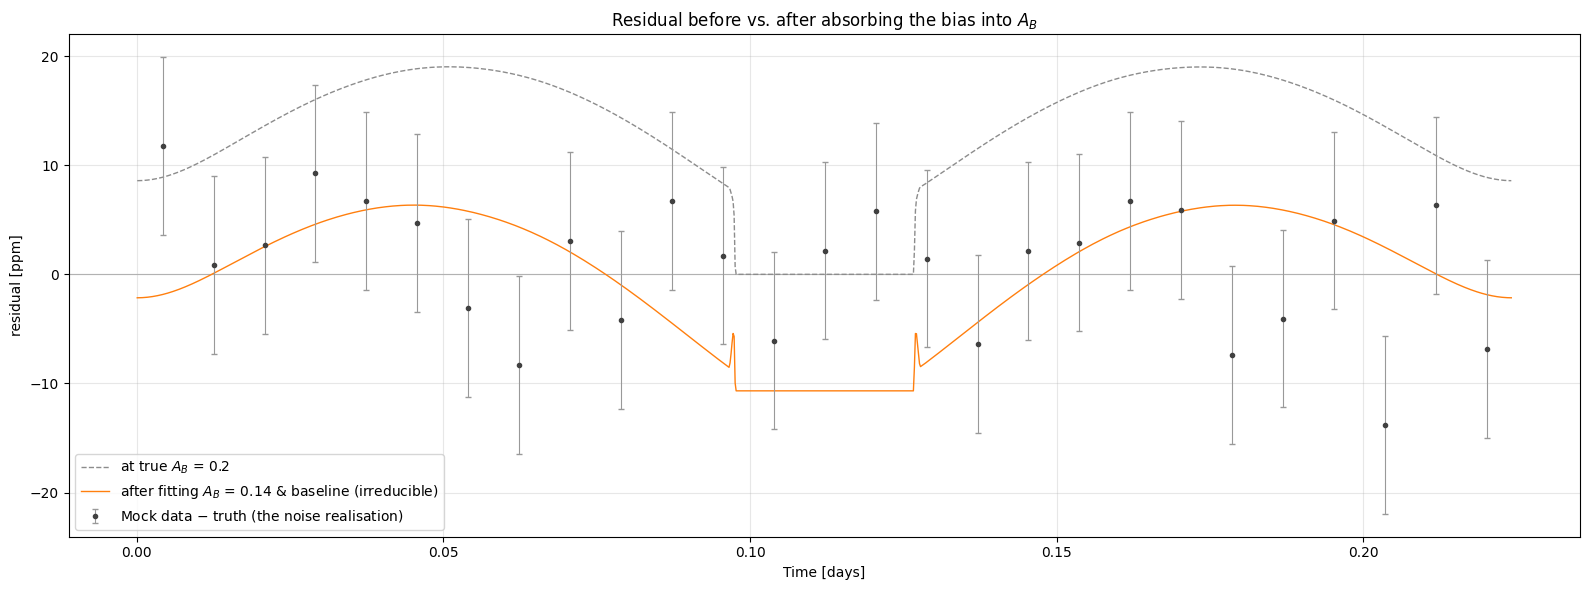

In [6]:
# before vs after absorbing the bias into A_B
t_, truth = model_pcurve(cfg, "hyperillum", A_B_true)
A_fit, _, _  = fit_naive(cfg, truth)
naive_0   = model_pcurve(cfg, "naive", A_B_true)[1]
naive_f   = model_pcurve(cfg, "naive", A_fit)[1]
naive_f   = naive_f + (truth - naive_f).mean()

# Mock observation, as in 1.: one draw ~ N(mean = hyperillumination truth, std = sigma_bin) per bin
tb, yb_truth = bin_curve(t_, truth, minutes_binning)
y_data = yb_truth + np.random.default_rng(SEED).normal(0., sigma_bin, size=yb_truth.size)   # same seed as the mock data in 1.
mock_kw = dict(fmt="o", ms=3, color="0.25", ecolor="0.6", elinewidth=.8, capsize=2, zorder=5)

# Figure 1: truth vs best-fit naive
fig, ax = plt.subplots(figsize=(16, 6))
ax.errorbar(tb, y_data, yerr=sigma_bin, label=rf"Mock data (hyperillumination $\pm\,{sigma_bin:.0f}$ ppm)", **mock_kw)
ax.plot(t_, truth,   lw=1, color="0.3", label="Hyperillumination (truth)")
ax.plot(t_, naive_f, lw=1, ls="--", color="C1", label=f"Best-fit naive ($A_B$={A_fit:.3f})")
ax.set_ylabel(r"$F_p/F_s$ [ppm]"); ax.set_xlabel("Time [days]")
ax.set_title("Indistinguishable by eye")
ax.grid(alpha=.3); ax.legend()
fig.tight_layout()
plt.show()

# Figure 2: both residuals combined on one axes, with the same mock data as the noise the bias has to beat
fig, ax = plt.subplots(figsize=(16, 6))
ax.axhline(0., color="0.7", lw=.8, zorder=1)
ax.errorbar(tb, y_data - yb_truth, yerr=sigma_bin, label=r"Mock data $-$ truth (the noise realisation)", **mock_kw)
ax.plot(t_, truth - naive_0, lw=1, ls="--", color="0.55", label=rf"at true $A_B$ = {A_B_true:.1f}")
ax.plot(t_, truth - naive_f, lw=1, color="C1", label=rf"after fitting $A_B$ = {A_fit:.2f} & baseline (irreducible)")
ax.set_ylabel("residual [ppm]"); ax.set_xlabel("Time [days]")
ax.set_title(r"Residual before vs. after absorbing the bias into $A_B$")
ax.grid(alpha=.3); ax.legend()
fig.tight_layout()
plt.show()

## 3. Bias vs the true $A_B$

The fit over a grid of true $A_B$: the absolute and relative bias, then its measurability $|\Delta A_B|/\sigma_{A_B}$ with the Fisher $\sigma$, whose right axis gives the noise per minute at which the bias is a $1\sigma$ effect. The fits may go below the physical floor (`A_B_FIT_BOUNDS`); dash-dot line: fitted $A_B = 0$.

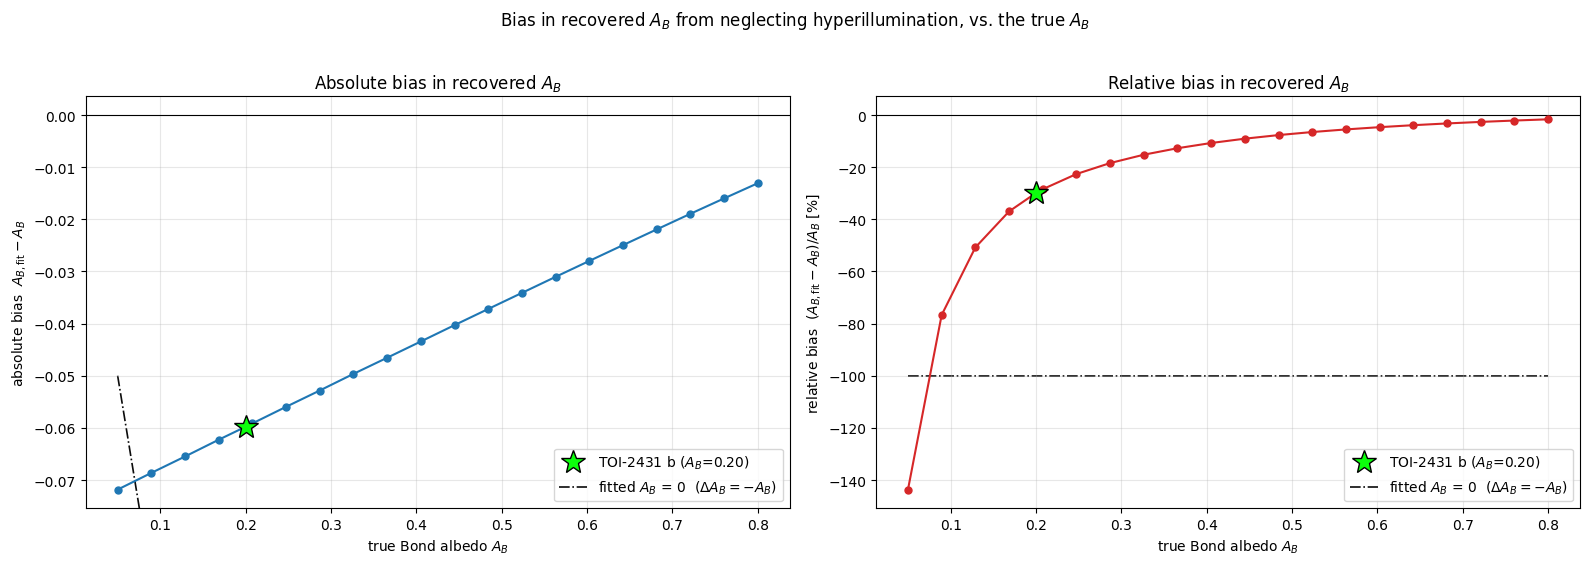

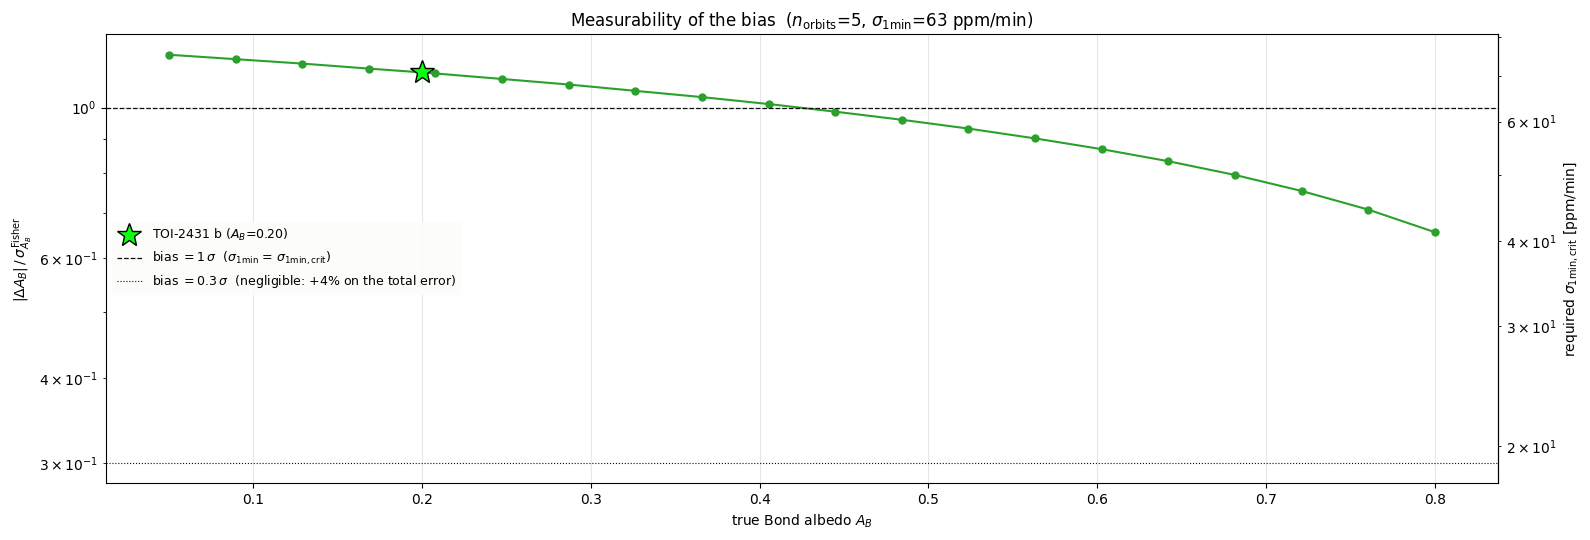

fitted A_B < 0 for true A_B <= 0.05
at TOI-2431 b (A_B=0.20): bias -0.0598,  sigma_A_B = 0.0531  ->  |bias|/sigma = 1.13
   sigma_1min = 62.9 ppm/min,  sigma_1min_crit = 70.9 ppm/min  ->  0.9x finer photometry, or 4 orbits instead of 5, before the bias reaches 1 sigma


In [7]:
# Vary the TRUE Bond albedo and refit the naive model at each value (single target geometry, free baseline). Bias = A_fit - A_B_true.
A_B_grid = np.unique(np.concatenate([np.linspace(0.05, 0.80, 20), [A_B_true]]))

# naive fit at each true A_B (A_fit in A_B_FIT_BOUNDS, so it can go below the physical floor 0) plus its Fisher sigma, evaluated at the FIT, where the naive posterior sits
sweep = bias_vs_true_AB(cfg, A_B_grid, redist=False)["naive"]
bias_abs, sigma_fisher = sweep["bias_A_B"], sweep["sigma_A_B"]
bias_rel = 100. * bias_abs / A_B_grid
bias_sigma, sigma_1min_crit = measurability(bias_abs, sigma_fisher, cfg.sigma_1min)   # |bias| in units of sigma_A_B at the CURRENT sigma_1min, and the per-minute precision at which |bias| = sigma_A_B
i0 = int(np.argmin(np.abs(A_B_grid - A_B_true)))   # nominal target point

below = A_B_grid + bias_abs < 0.   # fits below the physical floor A_B = 0
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))   # absolute | relative
for a_, y, y0, ylab, ttl, col in ((ax[0], bias_abs, -A_B_grid, r"absolute bias  $A_{B,\rm fit}-A_B$", "Absolute", "C0"),
                                  (ax[1], bias_rel, np.full(len(A_B_grid), -100.), r"relative bias  $(A_{B,\rm fit}-A_B)/A_B$ [%]", "Relative", "C3")):
    a_.axhline(0, color="k", lw=.8)
    a_.plot(A_B_grid, y, "o-", color=col, lw=1.5, ms=5)
    a_.plot(A_B_grid[i0], y[i0], "*", color="#0cff0c", ms=18, mec="k", label=f"{planet.name} ($A_B$={A_B_true:.2f})")
    if below.any():   # the fitted A_B = 0 reference line (Delta A_B = -A_B), as on the bias maps; the y range stays the data's
        lim = a_.get_ylim(); a_.plot(A_B_grid, y0, zorder=1.5, label=r"fitted $A_B$ = 0  ($\Delta A_B = -A_B$)", **FIT_ZERO); a_.set_ylim(lim)
    a_.set_xlabel(r"true Bond albedo $A_B$"); a_.set_ylabel(ylab)
    a_.set_title(ttl + r" bias in recovered $A_B$"); a_.grid(alpha=.3); a_.legend()
fig.suptitle("Bias in recovered $A_B$ from neglecting hyperillumination, vs. the true $A_B$", y=1.02)
fig.tight_layout()
plt.show()

# Is the bias measurable? |bias| / sigma_A_B, with sigma_A_B from the inverted Fisher matrix (offset marginalised, as in the fit).
# The right axis is the SAME curve scaled by cfg.sigma_1min: the per-minute precision at which the bias would be a 1-sigma effect.
# So the dashed horizontal line is where the instrument actually sits - the curve crossing it is the point where hyperillumination stops being ignorable.
fig, a_ = plt.subplots(figsize=(16, 5.5))
measurability_panel(a_, A_B_grid, [(bias_sigma, "o-", "C2", None)], i0, cfg, f"{planet.name} ($A_B$={A_B_true:.2f})",
                    r"$|\Delta A_B|\,/\,\sigma_{A_B}^{\rm Fisher}$",
                    r"Measurability of the bias  ($n_{\rm orbits}$=%d, $\sigma_{1\rm min}$=%.0f ppm/min)" % (cfg.n_orbits, cfg.sigma_1min))
a_.grid(alpha=.3)
fig.tight_layout()
plt.show()

fac = cfg.sigma_1min / sigma_1min_crit[i0]   # how much finer the photometry must get before the bias is a 1-sigma effect
print(f"fitted A_B < 0 for true A_B <= {A_B_grid[below].max():.2f}" if below.any() else "fitted A_B >= 0 at every true A_B of the grid")
print(f"at {planet.name} (A_B={A_B_true:.2f}): bias {bias_abs[i0]:+.4f},  sigma_A_B = {sigma_fisher[i0]:.4f}  ->  |bias|/sigma = {bias_sigma[i0]:.2f}")
print(f"   sigma_1min = {cfg.sigma_1min:.1f} ppm/min,  sigma_1min_crit = {sigma_1min_crit[i0]:.1f} ppm/min"
      f"  ->  {fac:.1f}x finer photometry, or {fac ** 2 * cfg.n_orbits:.0f} orbits instead of {cfg.n_orbits}, before the bias reaches 1 sigma")


## 4. Bias vs inclination

The bias maps of `03_bias_maps.ipynb` assume a central transit. Here only the inclination of the target is swept (`bias_sweep` with `cfg_with_incl`), down to the lowest inclination at which the occultation still spans `MIN_OCC_BINS` phase bins, in MIRI/LRS and the joint NIRSpec fit at the planet's own noise (independent of `instrument`); green star: the planet's own $i$.

inclination grid: 68-90 deg (occultation >= 3 of 27 bins below 90 deg; grazing below 61.9 deg)



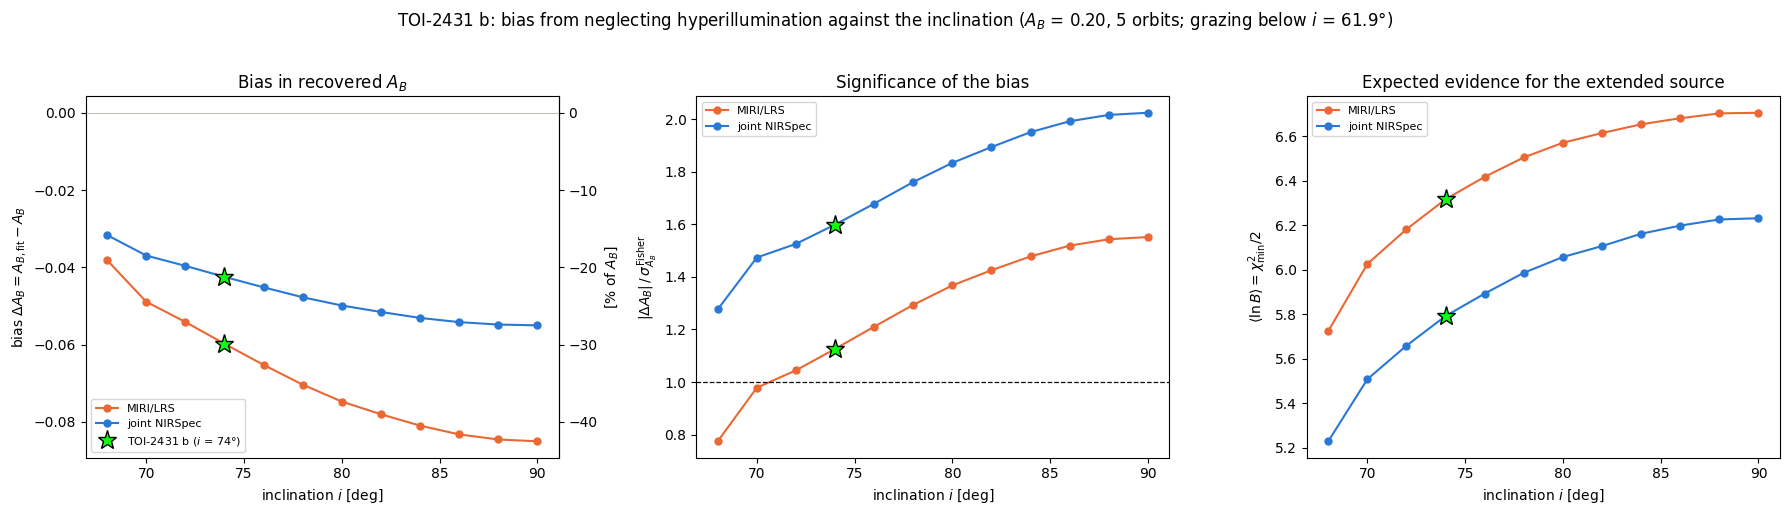

TOI-2431 b, MIRI/LRS  (value = inclination [deg])
 value  A_B_fit     bias   sigma  bias_sigma  chi2  lnB_mean
    90    0.115   -0.085 0.05478       1.552 13.41     6.707
    88   0.1155 -0.08453 0.05478       1.543 13.41     6.704
    86   0.1168 -0.08321 0.05479       1.519 13.36     6.682
    84   0.1191 -0.08095 0.05477       1.478 13.31     6.655
    82    0.122   -0.078 0.05473       1.425 13.23     6.615
    80   0.1253 -0.07472 0.05464       1.368 13.14     6.572
    78   0.1297 -0.07034 0.05438       1.294 13.01     6.506
    76   0.1348 -0.06524 0.05389       1.211 12.84     6.418
    74   0.1402 -0.05978 0.05308       1.126 12.64     6.318
    72   0.1459 -0.05413 0.05182       1.045 12.37     6.183
    70   0.1511  -0.0489 0.04997      0.9786 12.05     6.026
    68   0.1618 -0.03816 0.04925      0.7748 11.45     5.724 

TOI-2431 b, joint NIRSpec  (value = inclination [deg])
 value  A_B_fit     bias   sigma  bias_sigma  chi2  lnB_mean
    90    0.145   -0.055 0.02717       

In [8]:
# Modes of the sweeps (sections 4 and 5): MIRI/LRS and the joint NIRSpec fit, each at the planet's own noise; independent of `instrument` above
SWEEP_MODES = {"MIRI/LRS": "MIRI/LRS", "joint NIRSpec": tuple(JWST_BANDS[:2])}
kw_sweep = dict(n_lo=DEFAULT_N_LO, n_la=DEFAULT_N_LA)
sweep_cfgs = {label: retrieval_cfg(cfg, planet, ins) for label, ins in SWEEP_MODES.items()}

# Lowest inclination of the sweep: the occultation (as long as the transit on a circular orbit) must still span MIN_OCC_BINS phase bins; closer to grazing the fit depends on n_bins
MIN_OCC_BINS = 3
i_graze = np.degrees(np.arccos((1. - planet.r1 / planet.r2) / (planet.R / planet.r2)))   # b = 1 - Rp/R*: below it the occultation is grazing
i_whole = np.arange(np.ceil(i_graze), 90.5, 1.)   # whole degrees
long_enough = (transit_duration_t14(planet.period, planet.R / planet.r2, planet.r1 / planet.r2, pd.Series(i_whole)) >= MIN_OCC_BINS * planet.period * 24. / cfg.n_bins).to_numpy()
if not long_enough.any(): raise ValueError(f"the occultation spans fewer than {MIN_OCC_BINS} of {cfg.n_bins} bins even at i = 90 deg: lower MIN_OCC_BINS or raise n_bins")
i_min = i_whole[np.argmax(long_enough)]
if planet.incl < i_min: print(f"NOTE: the planet's own i = {planet.incl:g} deg is below the cut ({i_min:g} deg), so its own point depends on n_bins")
incl_grid = np.unique(np.concatenate([np.arange(90., i_min - 0.5, -2.), [i_min, planet.incl]]))[::-1]
print(f"inclination grid: {i_min:g}-90 deg (occultation >= {MIN_OCC_BINS} of {cfg.n_bins} bins below 90 deg; grazing below {i_graze:.1f} deg)\n")
sweeps_i = {label: bias_sweep(c, A_B_true, incl_grid, cfg_with_incl, models=("naive",), **kw_sweep) for label, c in sweep_cfgs.items()}

fig, _ = plot_bias_sweep(sweeps_i, A_B_true, r"inclination $i$ [deg]", joint=False, mark=planet.incl, mark_label=f"{planet.name} ($i$ = {planet.incl:g}°)",
                         title=f"{planet.name}: bias from neglecting hyperillumination against the inclination ($A_B$ = {A_B_true:.2f}, {cfg.n_orbits} orbits; grazing below $i$ = {i_graze:.1f}°)")
plt.show()
for label, t in sweeps_i.items():
    print(f"{planet.name}, {label}  (value = inclination [deg])")
    print(t[["value", "A_B_fit", "bias", "sigma", "bias_sigma", "chi2", "lnB_mean"]].to_string(index=False, float_format=lambda v: f"{v:.4g}"), "\n")

**A planet read off the map against its own inclination.** For the paper planets with the largest impact parameters (`check_planets`, $b > 0.5$), the $A_B$-only fit at $i = 90°$, where the map places them, and at their own inclination: the printed relative biases give the part of the difference between map and per-planet fit that is due to the inclination alone. Below `MIN_OCC_BINS` occultation bins the own-inclination value depends on `n_bins`.

In [9]:
check_planets = ("TOI-2431 b", "TOI-2260 b", "Kepler-78 b")   # the paper planets with b > 0.5, whose map value (i = 90 deg) overstates their own-geometry bias
mode0 = next(iter(SWEEP_MODES))
for nm in check_planets:
    pl_ = hi_planets_by_name(nm)
    t = bias_sweep(retrieval_cfg(cfg, pl_, SWEEP_MODES[mode0]), A_B_true, (90., pl_.incl), cfg_with_incl, models=("naive",), **kw_sweep)
    b = pl_.R / pl_.r2 * np.cos(np.radians(pl_.incl))
    occ_bins = transit_duration_t14(pl_.period, pl_.R / pl_.r2, pl_.r1 / pl_.r2, pd.Series([pl_.incl])).iloc[0] / (pl_.period * 24. / cfg.n_bins)   # occultation length at its own i [phase bins]
    print(f"{nm} ({mode0}, a/R* = {pl_.R / pl_.r2:.2f}, b = {b:.2f}, occultation {occ_bins:.1f} of {cfg.n_bins} bins): bias {t['bias'][0]:+.4f} ({100 * t['bias'][0] / A_B_true:+.0f} %) at i = 90 deg,  {t['bias'][1]:+.4f} ({100 * t['bias'][1] / A_B_true:+.0f} %) at its own i = {pl_.incl:g} deg;  "
          f"|bias|/sigma {t['bias_sigma'][0]:.2f} -> {t['bias_sigma'][1]:.2f}")

TOI-2431 b (MIRI/LRS, a/R* = 2.08, b = 0.57, occultation 3.8 of 27 bins): bias -0.0850 (-42 %) at i = 90 deg,  -0.0598 (-30 %) at its own i = 74 deg;  |bias|/sigma 1.55 -> 1.13


TOI-2260 b (MIRI/LRS, a/R* = 2.22, b = 0.77, occultation 2.8 of 27 bins): bias -0.0770 (-39 %) at i = 90 deg,  -0.0282 (-14 %) at its own i = 69.7 deg;  |bias|/sigma 0.53 -> 0.21


Kepler-78 b (MIRI/LRS, a/R* = 2.70, b = 0.69, occultation 2.5 of 27 bins): bias -0.0417 (-21 %) at i = 90 deg,  -0.0202 (-10 %) at its own i = 75.2 deg;  |bias|/sigma 0.14 -> 0.07


## 5. Bias vs the limb darkening $u_{\rm bol}$ of the irradiance

$u_{\rm bol}$ enters only the extended-source truth (the point-source model has none), so the sweep (`bias_sweep` with `cfg_with_u_bol`) changes the truth alone and refits it, in the two modes of section 4; green star: the baseline. It shows how much the bias and the expected evidence depend on the limb darkening over its plausible range.

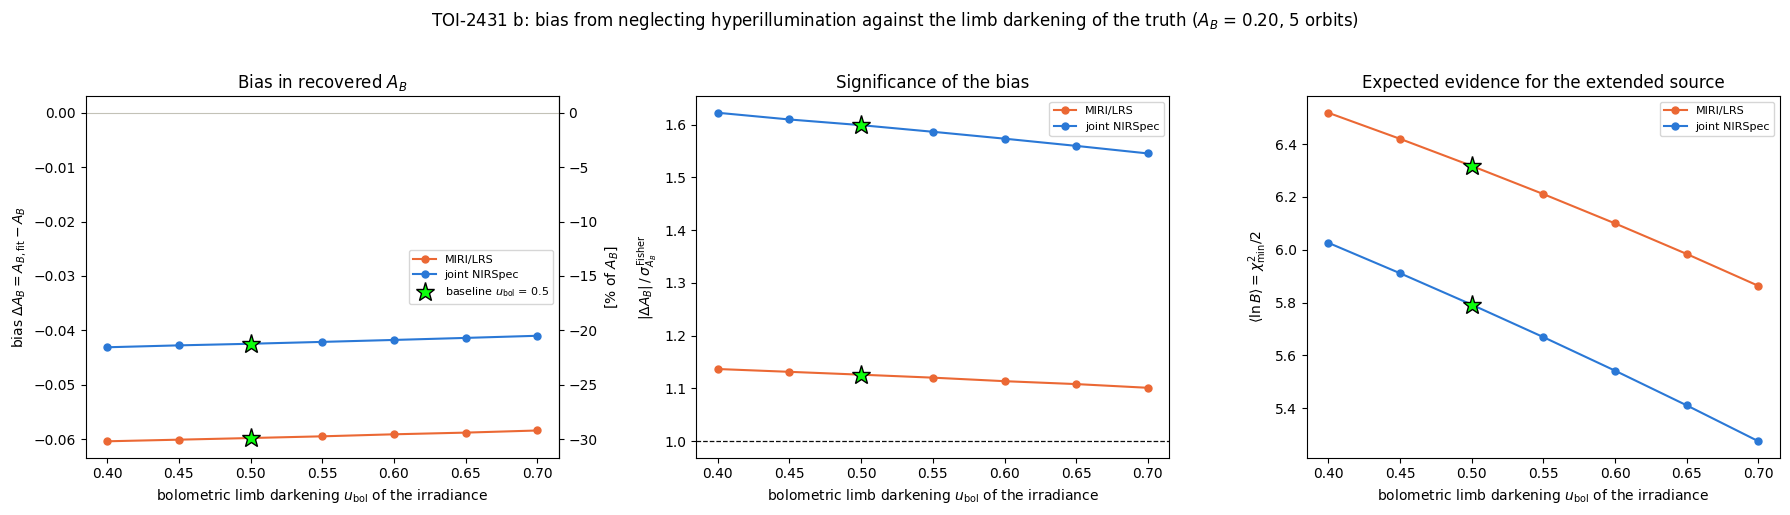

TOI-2431 b, MIRI/LRS  (value = u_bol)
 value  A_B_fit     bias   sigma  bias_sigma  chi2  lnB_mean
   0.4   0.1396 -0.06038 0.05311       1.137 13.04     6.519
  0.45   0.1399 -0.06008  0.0531       1.132 12.84      6.42
   0.5   0.1402 -0.05978 0.05308       1.126 12.64     6.318
  0.55   0.1405 -0.05946 0.05307       1.121 12.42     6.211
   0.6   0.1409 -0.05909 0.05305       1.114  12.2       6.1
  0.65   0.1412 -0.05878 0.05304       1.108 11.97     5.984
   0.7   0.1416 -0.05839 0.05302       1.101 11.73     5.863 

TOI-2431 b, joint NIRSpec  (value = u_bol)
 value  A_B_fit     bias   sigma  bias_sigma  chi2  lnB_mean
   0.4   0.1569  -0.0431 0.02657       1.622 12.05     6.026
  0.45   0.1573 -0.04275 0.02656        1.61 11.82     5.911
   0.5   0.1575 -0.04245 0.02655       1.599 11.58     5.792
  0.55   0.1579 -0.04211 0.02655       1.586 11.34     5.669
   0.6   0.1582 -0.04175 0.02654       1.573 11.08     5.542
  0.65   0.1586 -0.04138 0.02653       1.559 10.82      5.41
  

In [10]:
u_bol_grid = np.unique(np.round(np.concatenate([np.arange(0.40, 0.701, 0.05), [u_bol]]), 6))
sweeps_u = {label: bias_sweep(c, A_B_true, u_bol_grid, cfg_with_u_bol, models=("naive",), **kw_sweep) for label, c in sweep_cfgs.items()}

fig, _ = plot_bias_sweep(sweeps_u, A_B_true, r"bolometric limb darkening $u_{\rm bol}$ of the irradiance", joint=False, mark=u_bol, mark_label=f"baseline $u_{{\\rm bol}}$ = {u_bol:g}",
                         title=f"{planet.name}: bias from neglecting hyperillumination against the limb darkening of the truth ($A_B$ = {A_B_true:.2f}, {cfg.n_orbits} orbits)")
plt.show()
for label, t in sweeps_u.items():
    print(f"{planet.name}, {label}  (value = u_bol)")
    print(t[["value", "A_B_fit", "bias", "sigma", "bias_sigma", "chi2", "lnB_mean"]].to_string(index=False, float_format=lambda v: f"{v:.4g}"), "\n")